# Scientific assessment of nsb-py: observational performance and comparison with nsb2

### A reproducible assessment of optical night-sky radiance

How closely does **nsb-py** reproduce the measured night sky? This notebook is
written for astronomers, observers and scientific reviewers who want to assess
its predictive performance and understand the physical assumptions behind it.

NSB predicts photon radiance for an observing location, time and sky direction by
combining **airglow, zodiacal light, integrated starlight and scattered moonlight**.
Here we compare its predictions with flux-calibrated **Patat/FORS1 observations
at Paranal**, and with the independent implementation **nsb2**, over **365–650 nm**.
The observable is radiance in photons cm⁻² ns⁻¹ sr⁻¹, rather than detector counts
or a photometric magnitude. The selected observations are dark-time and moonless;
they do not test the moonlight model or NSB's entire default 300–650 nm band.

This assessment answers three questions:

1. **Observational agreement:** how large are the prediction errors and systematic biases?
2. **Comparative performance:** how does NSB compare with nsb2 and a simple empirical baseline?
3. **Physical interpretation:** what changes when Oxygen emission is included, and how sensitive are results to solar inputs?

Code: AGPL-3.0-only, Copyright (C) 2026 Vallés Puig, Ramon. Data retain source terms.


### Before running

Use a fresh **CPython 3.12 or 3.13** Jupyter kernel with these prerequisites:

```bash
python -m pip install nsb-py==0.2.0 nsb2 numpy astropy matplotlib siderust tempoch
```

The Python import is `nsb`; the distribution is **nsb-py**. The notebook is
standalone and requires no repository checkout or private service. First execution requires network
access to retrieve the observations and nsb2 reference inputs; verified local
caches are reused. Installed versions and input identities accompany the results.

The configuration cell below controls cache and output locations. Leave the
registered scientific settings unchanged to reproduce this experiment. Set
`OUTPUT = ""` to suppress exports; tables and figures are still displayed.


In [11]:
# Configure cache and exports, then Restart and Run All.
# The notebook uses the published nsb-py 0.2.0 release from PyPI.
import os
from pathlib import Path

NSB_VERSION = "0.2.0"
CACHE = Path(os.environ.get("NSB_VALIDATION_CACHE", str(Path.home() / ".cache/nsb-observational")))
OUTPUT = os.environ.get("NSB_VALIDATION_OUTPUT", "validation-results")

# Frozen protocol: changing these creates an incompatible experiment.
REPETITIONS, SEED, PRACTICAL_MARGIN = 2000, 182, 0.10


In [12]:
import ast
import hashlib
import importlib.metadata as metadata
import json
import platform
import sys
import re
import tarfile
import tempfile
import zipfile
from datetime import UTC, date, datetime, timedelta
from itertools import combinations
from types import SimpleNamespace
from urllib.request import urlopen

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.constants import c, h
from astropy.coordinates import AltAz, EarthLocation, SkyCoord
from astropy.io import fits
from astropy.time import Time
from astropy.utils import iers
from astropy.utils.data import cache_contents
from IPython import get_ipython
from IPython.display import Markdown, display
import nsb
import nsb2

iers.conf.auto_download = False
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
LABEL = "Patat development experiment"
display(Markdown(f"**{LABEL}**"))
# Registered Paranal geometry and comparison definitions.
SITE = {"longitude": -70.4045, "latitude": -24.6272, "height": 2635.0}
MODELS = ("NSB continuum", "NSB Automatic", "nsb2")
COMPONENTS = ("zodiacal", "airglow", "starlight", "moonlight")
DENSITY_UNIT = 1 / u.ns / u.cm**2 / u.sr / u.nm


**Patat development experiment**

In [13]:
def sha256(path):
    result = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            result.update(block)
    return result.hexdigest()


runtime_provenance = {
    "nsb": {"version": metadata.version("nsb-py"), "source": "pypi"},
    "nsb2": {"version": metadata.version("nsb2"), "source": "pypi"},
}

In [14]:
# v0.2.0 policy check: Automatic Airglow must match explicit Oxygen and exceed continuum.
import nsb
import siderust
from datetime import UTC, datetime

assert nsb.NsbModelConfig.generic_clear_sky().airglow_selection == "automatic"
observer = siderust.Observer(lon_deg=-70.4045, lat_deg=-24.6272, height_m=2635.0)
instant = datetime(2023, 9, 4, 1, 48, tzinfo=UTC)
target = siderust.Direction(ra_deg=0.0, dec_deg=-24.6272)
query = nsb.PointQuery(observer, instant, target, components=nsb.ComponentMask.AIRGLOW)
auto = float(nsb.NsbEvaluator(nsb.NsbModelConfig.generic_clear_sky()).integrate_band(query, 365.0, 650.0))
oxy = float(
    nsb.NsbEvaluator(
        nsb.NsbModelConfig.generic_clear_sky().with_airglow_model(nsb.AirglowModel.PARANAL_PALACE_OXYGEN_V1)
    ).integrate_band(query, 365.0, 650.0)
)
cont = float(
    nsb.NsbEvaluator(
        nsb.NsbModelConfig.generic_clear_sky().with_airglow_model(nsb.AirglowModel.PARANAL_PALACE_V1)
    ).integrate_band(query, 365.0, 650.0)
)
assert abs(auto - oxy) <= 1e-12 * max(1.0, abs(oxy)), (auto, oxy)
assert auto > cont, (auto, cont)
print(f"Automatic==Oxygen OK ({auto:.6f} ph cm^-2 ns^-1 sr^-1); continuum={cont:.6f}")


Automatic==Oxygen OK (0.208666 ph cm^-2 ns^-1 sr^-1); continuum=0.127034


## 1. Observations and scope

The [Patat (2008) FORS1 Night Sky Spectral Library](https://www.eso.org/~fpatat/science/skybright/)
provides flux-calibrated sky spectra at Paranal. The registered selection contains
**103 spectra from 22 nights**: nine spectra on five nights define the empirical
baseline; the remaining **94 spectra on 17 nights** are used for error assessment.
Several spectra from one night share observing conditions and are not independent nights.

The sample applies the following selection criteria:

- **Observing configuration:** DARKFLG=0, grism 300V and filter FREE.
- **Astronomical night:** Sun altitude < −18°.
- **Moonless conditions:** Moon altitude < −5° (the lunar-altitude cut adopted for this sample).
- **Airmass:** 1–1.5.
- **Galactic latitude:** |b| ≥20°.
- **Exposure time:** ≥60 s.
- **Spectral coverage:** complete 365–650 nm coverage.

These cuts define a restricted dark-sky regime, rather than a survey of all
observing conditions. Integer MJD defines the registered night.

For an energy spectrum $I_E$, the measured photon radiance is
$N=\int I_E(\lambda)\lambda/(hc)\,d\lambda$ over 365–650 nm.
The integration retains noisy negative spectral samples and handles the band
edges explicitly; the resulting integrated observations must be positive.
The exact measurement and input checks are documented in the appendix.


In [15]:
PATAT_SHA = "1f615fccb6dd464ab95b91f34adb4ba8ba3f4beebe97559204483c1da2c9965c"
PATAT_URLS = (
    "https://www.eso.org/~fpatat/science/skybright/DATA/skyspectra.tar",
    "https://web.archive.org/web/20160329190127id_/http://www.eso.org/~fpatat/science/skybright/DATA/skyspectra.tar",
)
SOLAR_SHA = "7240df111ea45f26057b89d3e9880a58856d7b6d040ad16247db41f5546dac96"
SOLAR_URL = (
    "https://www.ngdc.noaa.gov/stp/space-weather/solar-data/solar-features/"
    "solar-radio/noontime-flux/penticton/penticton_observed/listings/"
    "listing_drao_noontime-flux-observed_daily.txt"
)
CALIBRATION_NIGHTS = frozenset((51643, 51725, 51761, 51785, 52847))
# Exact SI constants expressed in cgs. 1 nm=10 A; 1 ns=1e-9 s.
HC_ERG_CM = 6.62607015e-27 * 2.99792458e10
ARCSEC2_PER_SR = (180 * 3600 / np.pi) ** 2
UNIT = "photons cm^-2 ns^-1 sr^-1"

COHORT_SHA = "3efdd3a0f3af19bfbc7615864f928b33fe22bcdbd6c67568fe317c059d44a1d6"


def acquire(path, expected, urls=()):
    """Reuse a verified cache entry; otherwise download and atomically publish it."""
    path = Path(path)
    if path.is_symlink():
        raise ValueError("Input cache cannot be a symlink")
    if path.exists():
        if sha256(path) != expected:
            raise ValueError(f"Checksum mismatch: {path}; quarantine it explicitly")
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    failures = []
    for url in urls:
        print(f"Acquiring {url}", flush=True)
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent) as out:
                with urlopen(url, timeout=45) as response:
                    while chunk := response.read(1024 * 1024):
                        out.write(chunk)
                        if out.tell() > 100_000_000:
                            raise ValueError("Input exceeds download size limit")
                out.flush()
                if sha256(out.name) != expected:
                    raise ValueError("Complete downloaded SHA-256 mismatch")
                # Hard link has exclusive-create semantics, so concurrent runs cannot overwrite.
                import os

                os.link(out.name, path)
            return path
        except Exception as error:
            failures.append(f"{url}: {type(error).__name__}: {error}")
    raise RuntimeError(
        "No verified input available; no substitute dataset used.\n" + "\n".join(failures)
    )


def extract(archive, destination, *, expected=PATAT_SHA):
    """Read regular flat FITS only; validate every TAR member before writing."""
    archive, destination = Path(archive), Path(destination)
    if sha256(archive) != expected:
        raise ValueError("Unverified archive")
    if any(p.is_symlink() for p in (destination, *destination.parents)):
        raise ValueError("Symlink in extraction destination")
    content = {}
    names = set()
    with tarfile.open(archive) as tar:
        for item in tar:
            name = Path(item.name)
            if (
                not item.isfile()
                or len(name.parts) != 1
                or name.is_absolute()
                or name.name in (".", "..")
                or item.name != name.name
                or item.name in names
                or item.size > 5_000_000
            ):
                raise ValueError(f"Unsafe/duplicate archive member: {item.name}")
            names.add(item.name)
            if item.name.startswith("fxSKY") and item.name.endswith(".fits"):
                content[item.name] = tar.extractfile(item).read()
    if not content:
        raise ValueError("No FITS in archive")
    inventory = {name: hashlib.sha256(data).hexdigest() for name, data in content.items()}
    if destination.exists():
        if {p.name for p in destination.iterdir()} != set(inventory):
            raise ValueError("Extracted inventory mismatch")
        for name, expected_digest in inventory.items():
            p = destination / name
            if p.is_symlink() or not p.is_file() or sha256(p) != expected_digest:
                raise ValueError(f"Extracted FITS changed: {name}")
    else:
        destination.parent.mkdir(parents=True, exist_ok=True)
        with tempfile.TemporaryDirectory(dir=destination.parent) as tmp:
            for name, data in content.items():
                (Path(tmp) / name).write_bytes(data)
            Path(tmp).rename(destination)
    return destination, inventory

In [16]:
def linear_integral(x, y, lower, upper):
    """Trapezoid with interpolated boundaries; never extrapolate."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    if (
        x.ndim != 1
        or x.size < 2
        or y.shape != x.shape
        or not np.isfinite(x).all()
        or not np.isfinite(y).all()
        or np.any(np.diff(x) <= 0)
        or not x[0] <= lower < upper <= x[-1]
    ):
        raise ValueError("Finite increasing full-coverage spectral samples required")
    nodes = np.r_[lower, x[(x > lower) & (x < upper)], upper]
    return float(np.trapezoid(np.interp(nodes, x, y), nodes))


def measured_radiance(wavelength_angstrom, energy, lower=365.0, upper=650.0):
    """Exact integral of lambda times piecewise-linear I_E, retaining noisy negatives.

    erg/s/cm2/A/arcsec2 -> photons/cm2/ns/sr. On each clipped interval,
    Simpson integration is exact for the quadratic product lambda*I_E.
    This differs from trapezoid integration of pre-converted photon samples.
    """
    wave = np.asarray(wavelength_angstrom, float)
    flux = np.asarray(energy, float)
    linear_integral(wave, flux, lower * 10, upper * 10)  # validate
    nodes = np.r_[lower * 10, wave[(wave > lower * 10) & (wave < upper * 10)], upper * 10]
    a, b = nodes[:-1], nodes[1:]
    mid = (a + b) / 2
    area = np.sum(
        (b - a)
        / 6
        * (
            a * np.interp(a, wave, flux)
            + 4 * mid * np.interp(mid, wave, flux)
            + b * np.interp(b, wave, flux)
        )
    )
    return float(area * 1e-8 / HC_ERG_CM * ARCSEC2_PER_SR * 1e-9)


def photon_density(wave_angstrom, energy):
    """Per-nm photon density; diagnostic only, broadband uses exact operator above."""
    return np.asarray(energy) * np.asarray(wave_angstrom) * 1e-8 / HC_ERG_CM * ARCSEC2_PER_SR * 1e-8


def exclusion(row):
    """Frozen sequential selection, including DARKFLG; boundaries are intentional."""
    cuts = (
        (row["dark"] != 0, "dark_flag"),
        (row["grism"] != "300V", "grism"),
        (row["filter"] != "FREE", "filter"),
        (row["sun_alt"] >= -18, "twilight"),
        (row["moon_alt"] >= -5, "moon"),
        (not 1 <= row["airmass"] <= 1.5, "airmass"),
        (abs(row["gal_lat"]) < 20, "galactic_latitude"),
        (row["exposure"] < 60, "exposure"),
        (row["wave"][0] > 3650 or row["wave"][-1] < 6500, "coverage"),
    )
    return next((reason for reject, reason in cuts if reject), None)


def load_cohort(directory, *, enforce_registration=True):
    rows, rejected = [], {}
    for path in sorted(Path(directory).glob("*.fits")):
        with fits.open(path) as hdus:
            hdr, flux = hdus[0].header, np.asarray(hdus[0].data, float)
            if hdr["BUNIT"].strip() != "erg/s/cm2/A/arcsec2":
                raise ValueError(f"Unexpected flux unit: {path.name}")
            wave = hdr["CRVAL1"] + (np.arange(hdr["NAXIS1"]) + 1 - hdr["CRPIX1"]) * hdr["CDELT1"]
            fields = {
                "mjd": "MJD-OBS",
                "ra": "RA",
                "dec": "DEC",
                "airmass": "AIRMASS",
                "sun_alt": "ALTSUN",
                "moon_alt": "ALTMOON",
                "gal_lat": "GALAT",
                "header_sfu": "SUNFLUX",
                "exposure": "ORIGEXP",
                "dark": "DARKFLG",
            }
            row = {key: float(hdr[value]) for key, value in fields.items()}
            if not np.isfinite(list(row.values())).all():
                raise ValueError(f"Nonfinite metadata: {path.name}")
            row.update(
                id=path.name,
                night=int(row["mjd"]),
                wave=wave,
                energy=flux,
                grism=hdr["GRISM"].strip(),
                filter=hdr["FILTER"].strip(),
            )
        reason = exclusion(row)
        if reason:
            rejected[row["id"]] = reason
            continue
        row["observed"] = measured_radiance(wave, flux)
        row["split"] = "calibration" if row["night"] in CALIBRATION_NIGHTS else "evaluation"
        if not np.isfinite(row["observed"]) or row["observed"] <= 0:
            raise ValueError("Nonpositive integrated observational radiance")
        rows.append(row)
    identities = "\n".join(f"{r['id']}:{r['night']}:{r['split']}" for r in rows).encode()
    identity_sha = hashlib.sha256(identities).hexdigest()
    if enforce_registration:
        if identity_sha != COHORT_SHA or len(rows) != 103:
            raise ValueError(
                "Selected observation identities/night partition differ from registration"
            )
    return rows, {
        "selected": len(rows),
        "nights": len({r["night"] for r in rows}),
        "excluded_ids": rejected,
        "identity_sha256": identity_sha,
    }

### Coverage of the observing conditions

The next outputs show the calibration/evaluation partition, radiance across the
observing dates and the sampled airmass distribution. They establish the empirical
range tested here. Clustering in date or airmass limits how broadly a mean error
can be interpreted; the observations do not establish calibration at another site.

Solar-input availability is reported explicitly. An unavailable scenario is not
replaced by a different dataset or silently omitted from a complete assessment.


In [17]:
def solar_windows(path, rows):
    """Only checksum-pinned NOAA full source or frozen factual slice is accepted."""
    path = Path(path)
    digest = sha256(path)
    if digest != SOLAR_SHA:
        raise ValueError("Unverified solar data; matched scenario unavailable")
    daily = {}
    for line in path.read_text().splitlines():
        fields = line.split()
        if len(fields) == 2 and fields[1] != ".":
            daily[date(int(fields[0][:4]), int(fields[0][4:6]), int(fields[0][6:8]))] = float(
                fields[1]
            )
    values = {}
    for row in rows:
        center = Time(row["mjd"], format="mjd").to_datetime().date()
        days = [center + timedelta(days=i) for i in range(-13, 14)]
        if any(d not in daily for d in days):
            raise ValueError("Incomplete centered 27-day solar window")
        sample = np.array([daily[d] for d in days], float)
        if not np.isfinite(sample).all() or np.any(sample <= 0):
            raise ValueError("Invalid solar input")
        values[row["id"]] = float(np.mean(sample))
    return values

| Partition | Spectra | Nights |
|---|---:|---:|
| calibration | 9 | 5 |
| evaluation | 94 | 17 |


**Scenario availability:** {'native': 'available', 'matched': 'available'}

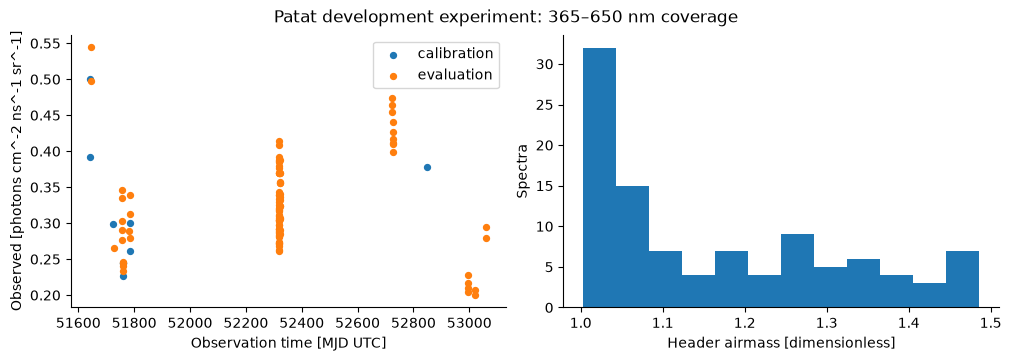

In [18]:
provenance = dict(runtime_provenance)
availability, failures = {}, []
predictions, metrics, spectral = {}, {}, None
from astropy.utils import data as astropy_data

astropy_data.conf.allow_internet = True
archive = acquire(CACHE / "skyspectra.tar", PATAT_SHA, PATAT_URLS)
library, inventory = extract(archive, CACHE / "library")
if len(inventory) != 1189:
    raise ValueError("Registered FITS product count changed")
rows, selection = load_cohort(library)
if (
    len({r["night"] for r in rows}),
    sum(r["split"] == "evaluation" for r in rows),
    len({r["night"] for r in rows if r["split"] == "evaluation"}),
) != (22, 94, 17):
    raise ValueError("Registered night/evaluation counts changed")
provenance.update(
    dataset={"sha256": PATAT_SHA, "urls": PATAT_URLS, "fits_inventory": inventory},
    selection=selection,
)
availability["native"] = "available"
try:
    solar = acquire(CACHE / "solar-observed.txt", SOLAR_SHA, (SOLAR_URL,))
    f27 = solar_windows(solar, rows)
    for row in rows:
        row["f27"] = f27[row["id"]]
    provenance["solar"] = {
        "input_sha256": sha256(solar),
        "source_sha256": SOLAR_SHA,
        "convention": "observed noontime; centered 27 complete UTC days",
        "outside_palace_training": sum(not 67 <= r["f27"] <= 166 for r in rows),
    }
    availability["matched"] = "available"
except (OSError, ValueError, RuntimeError) as error:
    availability["matched"] = f"UNAVAILABLE: {error}"

evaluation = np.array([i for i, r in enumerate(rows) if r["split"] == "evaluation"])
y = np.array([r["observed"] for r in rows])[evaluation]
coverage = "| Partition | Spectra | Nights |\n|---|---:|---:|\n"
for split in ("calibration", "evaluation"):
    subset = [r for r in rows if r["split"] == split]
    coverage += f"| {split} | {len(subset)} | {len({r['night'] for r in subset})} |\n"
display(Markdown(coverage))
display(Markdown("**Scenario availability:** " + str(availability)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for split in ("calibration", "evaluation"):
    subset = [r for r in rows if r["split"] == split]
    axes[0].scatter([r["mjd"] for r in subset], [r["observed"] for r in subset], label=split, s=18)
axes[0].set(xlabel="Observation time [MJD UTC]", ylabel=f"Observed [{UNIT}]")
axes[0].legend()
axes[1].hist([r["airmass"] for r in rows], bins=12)
axes[1].set(xlabel="Header airmass [dimensionless]", ylabel="Spectra")
fig.suptitle(f"{LABEL}: 365–650 nm coverage")
plt.show()

## 2. Comparison design

All configurations predict the same band-integrated observable for the same
observing times and directions. No telescope response is applied.

| Configuration | Role in the assessment |
|---|---|
| **NSB Automatic (Oxygen)** | nsb-py 0.2.0 default: PALACE continuum plus experimental Oxygen emission |
| **NSB continuum** | Controlled comparison with Oxygen excluded; other NSB assumptions remain fixed |
| **nsb2** | External implementation using Gaia starlight, Leinert zodiacal light and combined ESO SkyCalc Airglow |
| **Calibration baseline** | Constant median of the nine calibration spectra; tests whether physical predictions improve on a local empirical reference |

**Two solar scenarios answer different questions.** **Native** evaluates each
model with its own solar resolver: NSB's solar history and nsb2's Patat SUNFLUX
rounded to 0.1 sfu. **Matched** supplies an independently measured, centered
27-day observed F10.7 mean from NRC/Penticton via NOAA. It examines sensitivity
to a common solar input; it is not a refit to the sky observations. Both scenarios
are reported separately, rather than selecting whichever favors a model.

The matched nsb2 Airglow follows the registered rescaling
`(0.2 + 0.00614 × measured F27)/(0.2 + 0.00614 × native SUNFLUX)`.
PALACE's solar training range is **67–166 sfu**. Extrapolations are retained and
identified; observed/adjusted solar-convention equivalence is not assumed.

**Comparable totals require assumptions.** NSB's integrated Starlight map lacks
an admitted restricted-band spectral product. Its 365–650 nm contribution uses
the registered Rieke solar-photon fraction of the 300–650 nm map, a research-only
spectral proxy. nsb2's faint Gaia population (G≥15), propagation and Airglow
content differ from NSB's. Component names therefore do not imply identical
physical definitions. This experiment evaluates conditional research totals and
does not validate production spectral Starlight.


In [19]:
def reference_integral(wave, density, lower, upper):
    """Frozen nsb2/Rieke protocol: trapezoid on in-band source-grid nodes.

    Retained to compare with original evidence (not a new integration rule).
    The exact measured-energy operator is separate and inserts band edges.
    """
    wave, density = np.asarray(wave, float), np.asarray(density, float)
    if (
        wave.shape != density.shape
        or wave.ndim != 1
        or not np.isfinite(density).all()
        or not np.isfinite(wave).all()
        or np.any(np.diff(wave) <= 0)
        or wave[0] > lower
        or wave[-1] < upper
    ):
        raise ValueError("Invalid source spectrum or incomplete coverage")
    mask = (wave >= lower) & (wave <= upper)
    if np.count_nonzero(mask) < 2:
        raise ValueError("Insufficient in-band source-grid nodes")
    return float(np.trapezoid(density[mask], wave[mask]))


def starlight_fraction():
    from nsb2.core.photometry import SolarSpectrumRieke2008

    wave, energy = SolarSpectrumRieke2008()
    photon = (energy * wave / (h * c)).to_value(1 / u.s / u.cm**2 / u.nm)
    wave = wave.to_value(u.nm)
    return reference_integral(wave, photon, 365, 650) / reference_integral(wave, photon, 300, 650)


def prepare_nsb2_reference_assets():
    """Populate Astropy's URL-keyed cache using nsb2's published sources.

    There are no replacement spectra, alternative model inputs or silent
    scientific fallbacks. Cache hits avoid network access on repeated runs.
    """
    import time
    from urllib.error import HTTPError
    from astropy.utils.data import download_file, is_url_in_cache
    from nsb2.core.photometry import SOLAR_SPECTRUM_URL
    from nsb2.core.spectral import CALSPEC_URL, SVO_TABLE_URL, VEGA_CALSPEC_FILE
    from nsb2.emitter.stars import GAIA_MAP_URL

    inputs = (
        ("Rieke solar spectrum (STScI)", SOLAR_SPECTRUM_URL),
        ("Faint Gaia DR3 map (Zenodo)", GAIA_MAP_URL),
        ("Gaia G passband (SVO)", SVO_TABLE_URL + "GAIA/GAIA3.G"),
        ("Gaia Gbp passband (SVO)", SVO_TABLE_URL + "GAIA/GAIA3.Gbp"),
        ("Gaia Grp passband (SVO)", SVO_TABLE_URL + "GAIA/GAIA3.Grp"),
        ("Vega CALSPEC reference (STScI)", CALSPEC_URL + VEGA_CALSPEC_FILE),
    )
    inventory = {}
    for label, url in inputs:
        cached = is_url_in_cache(url)
        attempts = 1 if cached else 3
        for attempt in range(1, attempts + 1):
            try:
                file = download_file(
                    url, cache=True, show_progress=False, timeout=90
                )
                break
            except (OSError, TimeoutError) as error:
                if isinstance(error, HTTPError) and error.code in (400, 401, 403, 404, 410):
                    raise RuntimeError(
                        f"nsb2 asset '{label}' is unavailable (HTTP {error.code}): {url}. "
                        "The frozen scientific input cannot be replaced automatically."
                    ) from error
                if attempt == attempts:
                    raise RuntimeError(
                        f"Could not acquire nsb2 asset '{label}' after {attempts} "
                        f"attempt(s) (timeout 90s per request): {url}. "
                        "Check network access from the notebook runtime; retry later or "
                        "reuse a previously populated Astropy cache. "
                        "The observational comparison cannot use substituted data."
                    ) from error
                print(
                    f"  {label}: {type(error).__name__} on attempt "
                    f"{attempt}/{attempts}; retrying...", flush=True
                )
                time.sleep(min(attempt * 2, 5))
        inventory[url] = sha256(file)
        print(f"  {label}: {'cached' if cached else 'downloaded'}", flush=True)
    return inventory


def external_cache_inventory():
    """Record all Astropy data inputs, including nsb2's remote source assets."""
    return {url: sha256(path) for url, path in sorted(cache_contents().items())}

In [20]:
class Models:
    def __init__(self):
        import siderust
        from nsb2.emitter.stars import from_gaia_dr3_map
        from nsb2.emitter.zodiacal import from_leinert1998

        import nsb

        self.nsb, self.siderust = nsb, siderust
        self.observer = siderust.Observer(
            lon_deg=SITE["longitude"], lat_deg=SITE["latitude"], height_m=SITE["height"]
        )
        self.site = EarthLocation.from_geodetic(
            SITE["longitude"] * u.deg, SITE["latitude"] * u.deg, SITE["height"] * u.m
        )
        from astropy.utils import data as astropy_data
        astropy_data.conf.remote_timeout = 90
        print(
            "Preparing nsb2 reference assets (pinned upstream URLs; Astropy cache)",
            flush=True,
        )
        self.reference_assets = prepare_nsb2_reference_assets()
        self.fraction = starlight_fraction()
        self.zodiacal = from_leinert1998()
        self.stars = from_gaia_dr3_map()
        self.air_sources = {}

    def query(self, row, mask):
        return self.nsb.PointQuery(
            self.observer,
            Time(row["mjd"], format="mjd", scale="utc").to_datetime(timezone=UTC),
            self.siderust.Direction(ra_deg=row["ra"], dec_deg=row["dec"]),
            components=mask,
        )

    def nsb_components(self, row, oxygen, sfu=None):
        nsb = self.nsb
        # Automatic == Oxygen for v0.2.0; continuum must be selected explicitly.
        if oxygen:
            config = nsb.NsbModelConfig.generic_clear_sky()  # Automatic → Oxygen
        else:
            config = nsb.NsbModelConfig.generic_clear_sky().with_airglow_model(
                nsb.AirglowModel.PARANAL_PALACE_V1
            )
        if sfu is not None:
            config = config.with_solar_radio_flux_sfu(float(sfu))
        evaluator = nsb.NsbEvaluator(config)
        # Includes Moon explicitly: API must establish physical zero, not a fabricated band.
        mask = nsb.ComponentMask.ZODIACAL | nsb.ComponentMask.AIRGLOW | nsb.ComponentMask.MOON
        band = evaluator.integrate_band_components(self.query(row, mask), 365.0, 650.0)
        result = {
            component.name: float(component.integrated_photons_cm2_ns_sr)
            for component in band.components
        }
        # Runtime uses "moon" rather than the report's "moonlight" label.
        result["moonlight"] = result.pop("moon")
        if result["moonlight"] != 0.0:
            raise ValueError("Registered moonless assumption violated")
        star = evaluator.evaluate(self.query(row, nsb.ComponentMask.STARLIGHT))
        result["starlight"] = float(star.components[0].integrated_photons_cm2_ns_sr) * self.fraction
        return {key: result[key] for key in COMPONENTS}

    def source_integral(self, source, row):
        frame = AltAz(
            obstime=Time(row["mjd"], format="mjd", scale="utc"),
            location=self.site,
            pressure=0 * u.hPa,
        )
        direction = SkyCoord(ra=[row["ra"]] * u.deg, dec=[row["dec"]] * u.deg)
        field, _ = source.query_direct(SimpleNamespace(origin=frame), direction, np.zeros(1))
        wave = field.spectral_grid.wvl.to_value(u.nm)
        raw = field.spectral_grid(field.spectral_data)
        try:
            density = (raw[:, 0] * field.weights[0, 0]).to_value(DENSITY_UNIT)
        except u.UnitConversionError:
            density = None
        if density is None or density.shape != wave.shape:
            # The public resolver handles the source's photometric normalization units.
            from nsb2.core.spectral import Bandpass

            band = Bandpass(np.array([365.0, 400.0, 550.0, 650.0]) * u.nm, np.ones(4))
            rate = field.resolve_spectra(band).integrate()
            return (
                float(
                    np.asarray(
                        rate.to_value(
                            1 / u.s / u.cm**2 / u.sr, equivalencies=u.dimensionless_angles()
                        )
                    ).reshape(-1)[0]
                )
                * 1e-9
            )
        return reference_integral(wave, density, 365, 650)

    def nsb2_components(self, row, sfu=None):
        from nsb2.emitter.airglow import from_eso_skycalc

        # Native nsb2 protocol uses SUNFLUX rounded to 0.1 sfu. Matched diagnostic
        # scales that exact source by its scalar law, with unrounded measured f27.
        native_flux = round(row["header_sfu"], 1)
        if native_flux not in self.air_sources:
            self.air_sources[native_flux] = from_eso_skycalc(90 * u.km, native_flux)
        air = self.source_integral(self.air_sources[native_flux], row)
        if sfu is not None:
            air *= (0.2 + 0.00614 * sfu) / (0.2 + 0.00614 * native_flux)
        return {
            "zodiacal": self.source_integral(self.zodiacal, row),
            "airglow": air,
            "starlight": self.source_integral(self.stars, row),
            "moonlight": 0.0,
        }

    def predict(self, row, model, sfu=None):
        parts = (
            self.nsb2_components(row, sfu)
            if model == "nsb2"
            else self.nsb_components(row, model == "NSB Automatic", sfu)
        )
        if (
            set(parts) != set(COMPONENTS)
            or not np.isfinite(list(parts.values())).all()
            or min(parts.values()) < 0
        ):
            raise ValueError("Invalid/incomplete component prediction")
        return {"id": row["id"], "total": float(sum(parts.values())), "components": parts}

    def spectral_example(self, row, sfu=None):
        """Actual restricted API bin integrals, never an invented resolved line profile."""
        nsb = self.nsb
        bins = np.arange(550.0, 645.0, 1.0)
        result = {
            "id": row["id"],
            "air_wavelength_nm": (row["wave"] / 10).tolist(),
            "observed_total_density": photon_density(row["wave"], row["energy"]).tolist(),
            "vacuum_bin_edges_nm": bins.tolist(),
            "scenario": "native" if sfu is None else "matched",
        }
        for name, model in (
            ("continuum", nsb.AirglowModel.PARANAL_PALACE_V1),
            ("automatic", None),
            ("oxygen", nsb.AirglowModel.PARANAL_PALACE_OXYGEN_V1),
        ):
            cfg = nsb.NsbModelConfig.generic_clear_sky()
            if model is not None:
                cfg = cfg.with_airglow_model(model)
            if sfu is not None:
                cfg = cfg.with_solar_radio_flux_sfu(sfu)
            ev = nsb.NsbEvaluator(cfg)
            result[name] = [
                float(
                    ev.integrate_band(
                        self.query(row, nsb.ComponentMask.AIRGLOW), float(a), float(b)
                    )
                )
                for a, b in zip(bins[:-1], bins[1:], strict=True)
            ]
        return result


In [21]:
models = Models()
provenance["nsb2_reference_asset_sha256"] = models.reference_assets
provenance["starlight_band_fraction"] = models.fraction
for scenario, status in availability.items():
    if status != "available":
        continue
    predictions[scenario] = {m: [] for m in MODELS}
    for i, row in enumerate(rows):
        for model in MODELS:
            try:
                predictions[scenario][model].append(
                    models.predict(row, model, row["f27"] if scenario == "matched" else None)
                )
            except Exception as error:
                failures.append(
                    dict(scenario=scenario, model=model, id=row["id"], reason=str(error))
                )
        if (i + 1) % 25 == 0 or i + 1 == len(rows):
            print(f"{scenario}: {i + 1}/{len(rows)} spectra")
spectral = models.spectral_example(rows[0], rows[0].get("f27"))
provenance["astropy_input_cache"] = external_cache_inventory()
display(
    Markdown(
        f"**Rejected predictions: {len(failures)}** (IDs and reasons retained in result record)."
    )
)

Preparing nsb2 reference assets (pinned upstream URLs; Astropy cache)
  Rieke solar spectrum (STScI): cached
  Faint Gaia DR3 map (Zenodo): cached
  Gaia G passband (SVO): cached
  Gaia Gbp passband (SVO): cached
  Gaia Grp passband (SVO): cached
  Vega CALSPEC reference (STScI): cached
native: 25/103 spectra
native: 50/103 spectra
native: 75/103 spectra
native: 100/103 spectra
native: 103/103 spectra
matched: 25/103 spectra
matched: 50/103 spectra
matched: 75/103 spectra
matched: 100/103 spectra
matched: 103/103 spectra


**Rejected predictions: 0** (IDs and reasons retained in result record).

### How performance and uncertainty are measured

Residual = prediction − observation: positive bias means a sky prediction that is
too bright. **Mean absolute relative error (relative MAE)** measures the mean
of $|N_{pred}-N_{obs}|/N_{obs}$; **relative bias** is the mean of
$(N_{pred}-N_{obs})/N_{obs}$.
Both are displayed as percentages. MAE and RMSE retain radiance units. Each
spectrum has equal weight, regardless of exposure duration.

The baseline is fitted only on the calibration nights. For uncertainty we resample
**whole evaluation nights**, pairing the same draws across all configurations:
2,000 repetitions with seed 182. The percentile 95% intervals describe night-sampling
variability conditional on the fixed baseline, and exclude shared calibration systematics.
They are not prediction intervals for a new observation.

For paired relative-MAE differences, negative **NSB minus reference** favors NSB;
positive favors the reference. Differences are shown in **percentage points (pp)**.
An interval crossing zero establishes neither a difference nor equivalence.
The registered practical margin is **10 pp**: a practical directional claim
requires the entire paired interval beyond that margin.

Every model must predict all 103 spectra before a scenario can be scored on its
94 evaluation spectra. Missing or invalid predictions invalidate that scenario;
no subset is selected to improve agreement.


In [22]:
def align(rows, predictions):
    """Exact identifier matching; reject duplicates, extras, missing/nonfinite predictions."""
    ids = [r["id"] for r in rows]
    if not ids or len(set(ids)) != len(ids):
        raise ValueError("Unique nonempty observation identities required")
    result = {}
    missing = {}
    for model, records in predictions.items():
        mapping = {r["id"]: r for r in records}
        missing[model] = sorted(set(ids) - set(mapping))
        if len(mapping) != len(records) or set(mapping) != set(ids):
            raise ValueError(f"{model}: cohort mismatch; missing={missing[model]}")
        values = np.array([mapping[key]["total"] for key in ids], float)
        if not np.isfinite(values).all() or np.any(values < 0):
            raise ValueError(f"{model}: invalid predictions")
        result[model] = values
    return result


def baseline(rows):
    train = [r for r in rows if r["split"] == "calibration"]
    test = [r for r in rows if r["split"] == "evaluation"]
    if not train or not test or set(r["night"] for r in train) & set(r["night"] for r in test):
        raise ValueError("Disjoint nonempty calibration and evaluation nights required")
    return float(np.median([r["observed"] for r in train]))


def errors(observed, predicted):
    y, p = np.asarray(observed, float), np.asarray(predicted, float)
    if (
        y.ndim != 1
        or y.size == 0
        or y.shape != p.shape
        or not np.isfinite(y).all()
        or not np.isfinite(p).all()
        or np.any(y <= 0)
    ):
        raise ValueError("Finite aligned vectors and positive observations required")
    d = p - y
    rel = d / y
    with np.errstate(over="raise", invalid="raise", divide="raise"):
        values = {
            "mean_signed_error": np.mean(d),
            "mae": np.mean(abs(d)),
            "rmse": np.linalg.norm(d / np.sqrt(len(d))),
            "median_absolute_error": np.median(abs(d)),
            "mean_absolute_relative_error": np.mean(abs(rel)),
            "median_absolute_relative_error": np.median(abs(rel)),
            "relative_bias": np.mean(rel),
            "relative_rmse": np.linalg.norm(rel / np.sqrt(len(rel))),
        }
    if not np.isfinite(list(values.values())).all():
        raise ValueError("Unstable metric values")
    return {k: float(v) for k, v in values.items()}


def scores(observed, predictions, nights, repetitions=2000, seed=182):
    y, nights = np.asarray(observed, float), np.asarray(nights)
    if nights.shape != y.shape or repetitions < 100 or not predictions:
        raise ValueError("Matching nights, models and >=100 repetitions required")
    groups = [np.flatnonzero(nights == n) for n in np.unique(nights)]
    if len(groups) < 3:
        raise ValueError("At least three independent nights required for intervals")
    predictions = {k: np.asarray(v, float) for k, v in predictions.items()}
    metrics = {
        k: {**errors(y, p), "n": len(y), "nights": len(groups), "missing": 0}
        for k, p in predictions.items()
    }
    rng = np.random.default_rng(seed)
    draws = {k: np.empty((repetitions, 2)) for k in predictions}
    for i in range(repetitions):
        indices = np.concatenate([groups[j] for j in rng.integers(len(groups), size=len(groups))])
        for key, p in predictions.items():
            delta = abs(p[indices] - y[indices])
            draws[key][i] = (np.mean(delta), np.mean(delta / y[indices]))
    for key in predictions:
        metrics[key]["mae_ci95"] = np.percentile(draws[key][:, 0], [2.5, 97.5]).tolist()
        metrics[key]["relative_mae_ci95"] = np.percentile(draws[key][:, 1], [2.5, 97.5]).tolist()
    paired = {}
    for a, b in combinations(predictions, 2):
        paired[f"{a}_minus_{b}"] = {
            "mae_difference": metrics[a]["mae"] - metrics[b]["mae"],
            "relative_mae_difference": metrics[a]["mean_absolute_relative_error"]
            - metrics[b]["mean_absolute_relative_error"],
            "mae_ci95": np.percentile(draws[a][:, 0] - draws[b][:, 0], [2.5, 97.5]).tolist(),
            "relative_mae_ci95": np.percentile(
                draws[a][:, 1] - draws[b][:, 1], [2.5, 97.5]
            ).tolist(),
        }
    return {
        "models": metrics,
        "paired": paired,
        "repetitions": repetitions,
        "seed": seed,
        "estimand": "equal weight per spectrum (historically called exposure-weighted); resample whole nights",
        "interval_scope": "sampling variability conditional on fixed calibration baseline; no calibration-systematic uncertainty",
    }

In [23]:
baseline_value = baseline(rows)
provenance["baseline"] = {
    "value": baseline_value,
    "fit": "calibration-only spectrum median",
    "nights": sorted({r["night"] for r in rows if r["split"] == "calibration"}),
}
for scenario, records in predictions.items():
    try:
        vectors = align(rows, records)
        if set(vectors) != set(MODELS):
            raise ValueError("Required model missing")
    except ValueError as error:
        availability[scenario] = f"INVALID: {error}; no intersection scoring"
        continue
    vectors["baseline"] = np.full(len(rows), baseline_value)
    metrics[scenario] = scores(
        y,
        {k: v[evaluation] for k, v in vectors.items()},
        [rows[i]["night"] for i in evaluation],
        REPETITIONS,
        SEED,
    )
    for pair, p in metrics[scenario]["paired"].items():
        lo, hi = p["relative_mae_ci95"]
        decision = (
            "no demonstrated difference"
            if lo <= 0 <= hi
            else "left practically lower"
            if hi < -PRACTICAL_MARGIN
            else "right practically lower"
            if lo > PRACTICAL_MARGIN
            else "direction detected; practical margin not established"
        )
        p["interpretation"] = decision


## 3. Measured performance

The tables below give the numerical assessment for each solar scenario. Read the
mean errors alongside their night-based uncertainty and the **paired** comparisons;
a smaller point estimate alone does not establish superiority. The local baseline
is included even when it outperforms a physical model.


In [24]:
DISPLAY_NAMES = {"NSB Automatic": "NSB Automatic (Oxygen)", "NSB continuum": "NSB continuum", "nsb2": "nsb2", "baseline": "Calibration baseline"}
COLORS = {"NSB Automatic": "#0072B2", "NSB continuum": "#D55E00", "nsb2": "#009E73", "baseline": "#777777"}
SCENARIOS = {"native": "Native solar inputs", "matched": "Matched measured F10.7"}


def paired_comparison(result, left, right):
    # Preserve the record's original pair order; invert only the displayed direction.
    direct = f"{left}_minus_{right}"
    reverse = f"{right}_minus_{left}"
    if direct in result["paired"]:
        p = result["paired"][direct]
        return p["relative_mae_difference"], np.array(p["relative_mae_ci95"])
    p = result["paired"][reverse]
    return -p["relative_mae_difference"], -np.array(p["relative_mae_ci95"])[::-1]


def comparison_text(difference, interval, reference):
    lo, hi = interval
    if lo <= 0 <= hi:
        finding = "no difference established; equivalence is not established either"
    elif hi < 0:
        finding = "lower NSB error"
    else:
        finding = "higher NSB error"
    practical = "registered 10 pp practical margin established" if hi < -PRACTICAL_MARGIN or lo > PRACTICAL_MARGIN else "registered 10 pp practical margin not established"
    return (f"**NSB Automatic − {reference}: {100*difference:+.2f} pp** "
            f"(paired 95% CI {100*lo:+.2f} to {100*hi:+.2f} pp): {finding}; {practical}.")


if set(metrics) != {"native", "matched"} or failures:
    display(Markdown("**Incomplete assessment:** valid scenario results below are descriptive only. No overall comparative conclusion is drawn."))

for scenario in ("native", "matched"):
    if scenario not in metrics:
        display(Markdown(f"### {SCENARIOS[scenario]} — unavailable or invalid\n\n{availability.get(scenario, 'Not evaluated')}. No performance conclusion is drawn."))
        continue
    result = metrics[scenario]
    table = f"### {SCENARIOS[scenario]}\n\n"
    table += "| Model | Relative MAE [95% night CI] | Relative bias | MAE | RMSE |\n|---|---:|---:|---:|---:|\n"
    for name in ("NSB Automatic", "nsb2", "NSB continuum", "baseline"):
        m = result["models"][name]
        lo, hi = m["relative_mae_ci95"]
        table += (f"| {DISPLAY_NAMES[name]} | {100*m['mean_absolute_relative_error']:.2f}% "
                  f"[{100*lo:.2f}, {100*hi:.2f}]% | {100*m['relative_bias']:+.2f}% | "
                  f"{m['mae']:.5f} | {m['rmse']:.5f} |\n")
    display(Markdown(table + f"\nMAE and RMSE: {UNIT}. Relative bias is a point estimate; its interval is not estimated by this protocol."))
    m = result["models"]["NSB Automatic"]
    display(Markdown(f"NSB Automatic's mean absolute relative error is **{100*m['mean_absolute_relative_error']:.2f}%** across **{m['n']} spectra / {m['nights']} nights**. Its signed relative bias is **{100*m['relative_bias']:+.2f}%**, indicating {'overprediction' if m['relative_bias'] > 0 else 'underprediction' if m['relative_bias'] < 0 else 'no mean signed relative offset'}."))
    for reference in ("nsb2", "baseline", "NSB continuum"):
        difference, interval = paired_comparison(result, "NSB Automatic", reference)
        display(Markdown(comparison_text(difference, interval, DISPLAY_NAMES[reference])))


### Native solar inputs

| Model | Relative MAE [95% night CI] | Relative bias | MAE | RMSE |
|---|---:|---:|---:|---:|
| NSB Automatic (Oxygen) | 23.88% [20.70, 27.89]% | -23.88% | 0.08146 | 0.09291 |
| nsb2 | 17.09% [13.46, 20.96]% | +6.88% | 0.05395 | 0.06423 |
| NSB continuum | 36.10% [33.22, 39.53]% | -36.10% | 0.12139 | 0.13146 |
| Calibration baseline | 15.25% [10.62, 22.32]% | -4.33% | 0.05201 | 0.07084 |

MAE and RMSE: photons cm^-2 ns^-1 sr^-1. Relative bias is a point estimate; its interval is not estimated by this protocol.

NSB Automatic's mean absolute relative error is **23.88%** across **94 spectra / 17 nights**. Its signed relative bias is **-23.88%**, indicating underprediction.

**NSB Automatic − nsb2: +6.80 pp** (paired 95% CI +1.03 to +12.85 pp): higher NSB error; registered 10 pp practical margin not established.

**NSB Automatic − Calibration baseline: +8.64 pp** (paired 95% CI +1.03 to +13.51 pp): higher NSB error; registered 10 pp practical margin not established.

**NSB Automatic − NSB continuum: -12.22 pp** (paired 95% CI -12.85 to -11.17 pp): lower NSB error; registered 10 pp practical margin established.

### Matched measured F10.7

| Model | Relative MAE [95% night CI] | Relative bias | MAE | RMSE |
|---|---:|---:|---:|---:|
| NSB Automatic (Oxygen) | 16.57% [12.97, 22.61]% | -16.03% | 0.05750 | 0.07229 |
| nsb2 | 17.42% [14.35, 20.21]% | +8.13% | 0.05500 | 0.06363 |
| NSB continuum | 35.03% [32.14, 38.13]% | -35.03% | 0.11807 | 0.12827 |
| Calibration baseline | 15.25% [10.62, 22.32]% | -4.33% | 0.05201 | 0.07084 |

MAE and RMSE: photons cm^-2 ns^-1 sr^-1. Relative bias is a point estimate; its interval is not estimated by this protocol.

NSB Automatic's mean absolute relative error is **16.57%** across **94 spectra / 17 nights**. Its signed relative bias is **-16.03%**, indicating underprediction.

**NSB Automatic − nsb2: -0.85 pp** (paired 95% CI -5.71 to +5.58 pp): no difference established; equivalence is not established either; registered 10 pp practical margin not established.

**NSB Automatic − Calibration baseline: +1.33 pp** (paired 95% CI -4.61 to +6.08 pp): no difference established; equivalence is not established either; registered 10 pp practical margin not established.

**NSB Automatic − NSB continuum: -18.45 pp** (paired 95% CI -20.29 to -14.44 pp): lower NSB error; registered 10 pp practical margin established.

### Agreement with the measured sky

Points on the diagonal reproduce the observations; points below it underpredict
the sky. The dotted horizontal line is the fitted calibration baseline. Shared
residual bins make biases and error tails comparable across models: zero is exact
agreement, negative values are too faint and positive values are too bright.


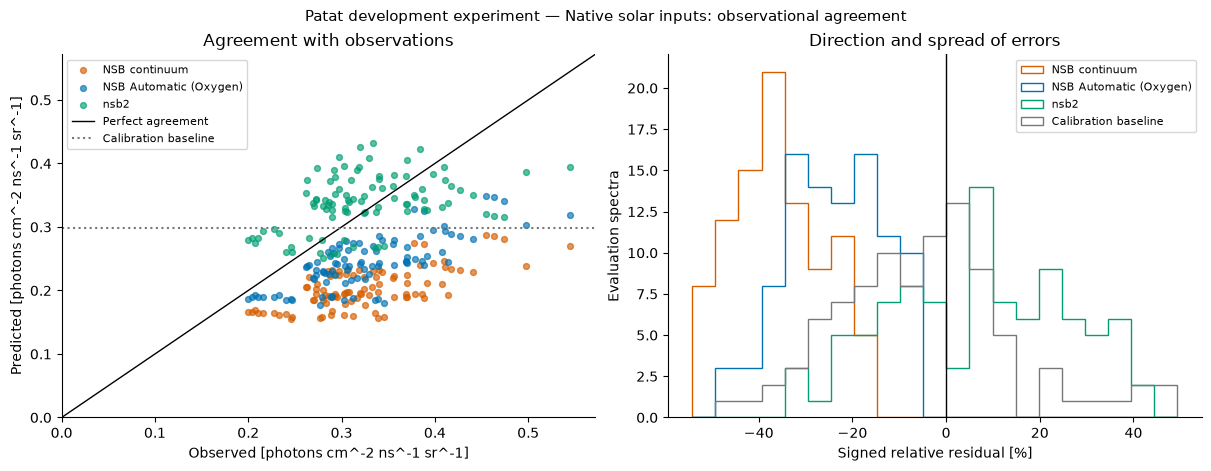

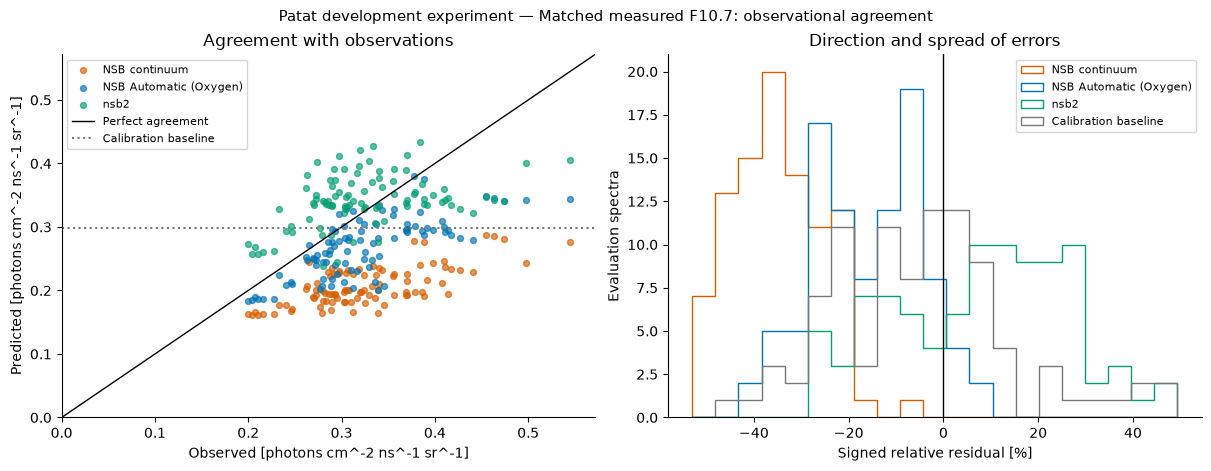

In [25]:
def show_figure(fig, name):
    fig.suptitle(f"{LABEL} — {name}", fontsize=11)
    plt.show()


def evaluation_values(scenario):
    return {m: np.array([r["total"] for r in predictions[scenario][m]])[evaluation] for m in MODELS}


for scenario, result in metrics.items():
    values = evaluation_values(scenario)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
    for model, predicted in values.items():
        axes[0].scatter(y, predicted, s=18, alpha=0.65, color=COLORS[model], label=DISPLAY_NAMES[model])
    high = max(y.max(), *(p.max() for p in values.values())) * 1.05
    axes[0].plot([0, high], [0, high], color="black", lw=1, label="Perfect agreement")
    axes[0].axhline(baseline_value, color=COLORS["baseline"], ls=":", label="Calibration baseline")
    axes[0].set(xlabel=f"Observed [{UNIT}]", ylabel=f"Predicted [{UNIT}]", title="Agreement with observations", xlim=(0, high), ylim=(0, high))
    axes[0].legend(fontsize=8)
    residuals = {m: 100 * (p - y) / y for m, p in values.items()}
    baseline_residual = 100 * (baseline_value - y) / y
    bins = np.linspace(min(baseline_residual.min(), *(r.min() for r in residuals.values())), max(baseline_residual.max(), *(r.max() for r in residuals.values())), 22)
    for model, residual in {**residuals, "baseline": baseline_residual}.items():
        axes[1].hist(residual, bins=bins, histtype="step", color=COLORS[model], label=DISPLAY_NAMES[model])
    axes[1].axvline(0, color="black", lw=1)
    axes[1].set(xlabel="Signed relative residual [%]", ylabel="Evaluation spectra", title="Direction and spread of errors")
    axes[1].legend(fontsize=8)
    show_figure(fig, f"{SCENARIOS[scenario]}: observational agreement")


### Is the model difference resolved?

The left panel compares error magnitudes with 95% night-sampling intervals. The
right panel directly tests paired differences for NSB Automatic against nsb2,
the baseline and continuum. Use these paired intervals, rather than overlap of
individual-model intervals, to assess differences. Negative favors NSB Automatic;
zero means equal error in that draw. Dotted lines mark the registered ±10 pp margin.


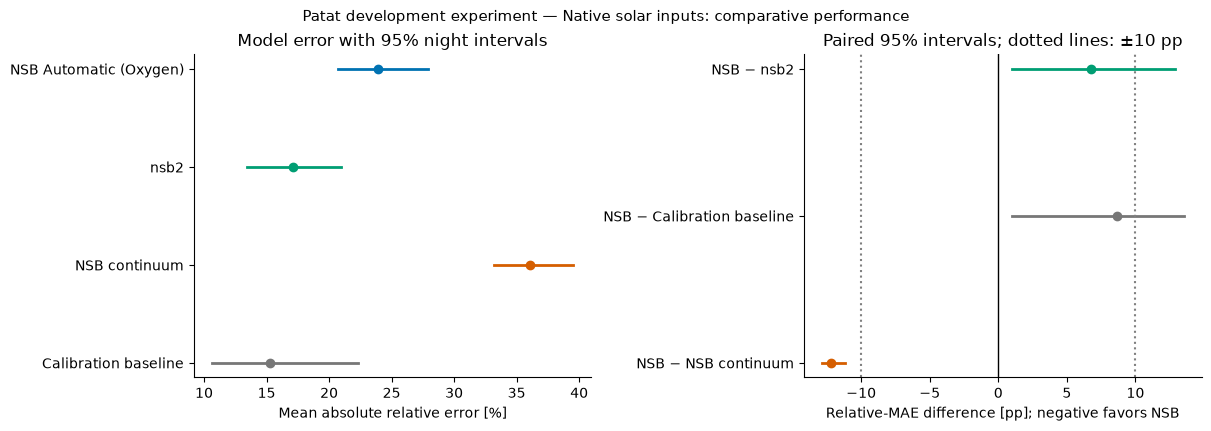

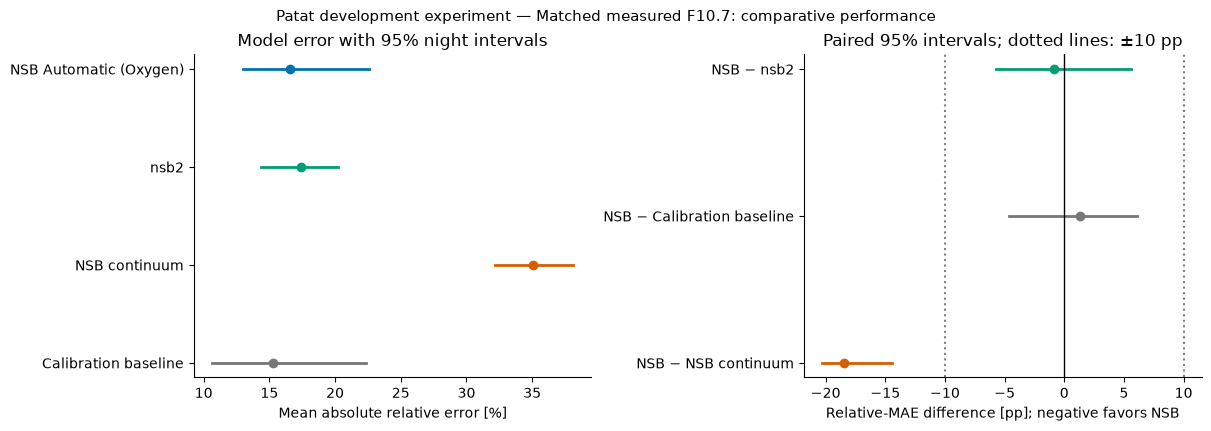

In [26]:
for scenario, result in metrics.items():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
    names = ("NSB Automatic", "nsb2", "NSB continuum", "baseline")
    for j, name in enumerate(names):
        m = result["models"][name]
        axes[0].plot(100*np.array(m["relative_mae_ci95"]), [j, j], color=COLORS[name], lw=2)
        axes[0].scatter(100*m["mean_absolute_relative_error"], j, color=COLORS[name])
    axes[0].set(yticks=range(len(names)), yticklabels=[DISPLAY_NAMES[m] for m in names], xlabel="Mean absolute relative error [%]", title="Model error with 95% night intervals")
    axes[0].invert_yaxis()
    references = ("nsb2", "baseline", "NSB continuum")
    for j, reference in enumerate(references):
        delta, interval = paired_comparison(result, "NSB Automatic", reference)
        axes[1].plot(100*interval, [j, j], color=COLORS[reference], lw=2)
        axes[1].scatter(100*delta, j, color=COLORS[reference])
    axes[1].axvline(0, color="black", lw=1)
    axes[1].axvline(-100*PRACTICAL_MARGIN, color="grey", ls=":")
    axes[1].axvline(100*PRACTICAL_MARGIN, color="grey", ls=":")
    axes[1].set(yticks=range(len(references)), yticklabels=[f"NSB − {DISPLAY_NAMES[r]}" for r in references], xlabel="Relative-MAE difference [pp]; negative favors NSB", title="Paired 95% intervals; dotted lines: ±10 pp")
    axes[1].invert_yaxis()
    show_figure(fig, f"{SCENARIOS[scenario]}: comparative performance")


## 4. Physical interpretation and diagnostics

### Variation across nights and the effect of Oxygen

Night means reveal whether a bias persists or is concentrated in a few observing
nights; connecting lines are visual guides, not an interpolation of missing nights.
The per-spectrum bars isolate the change from continuum to Oxygen: blue indicates
reduced absolute error, orange increased error. A mean improvement need not benefit
every observation.

The component budget then places the modeled sources beside the mean observed
total. It helps locate differences in the radiance budget, but component definitions
and populations differ across implementations. It is not a component-by-component
observational validation.


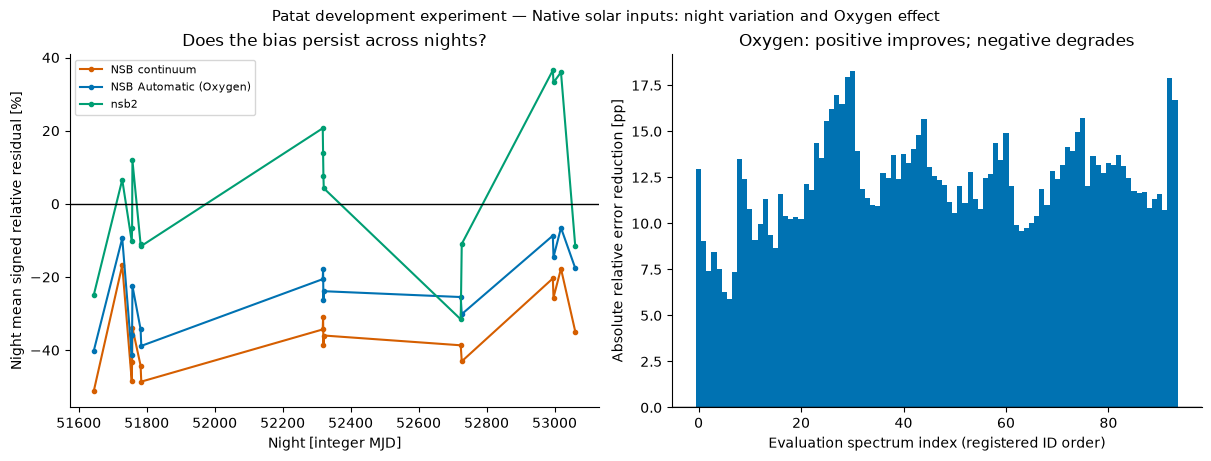

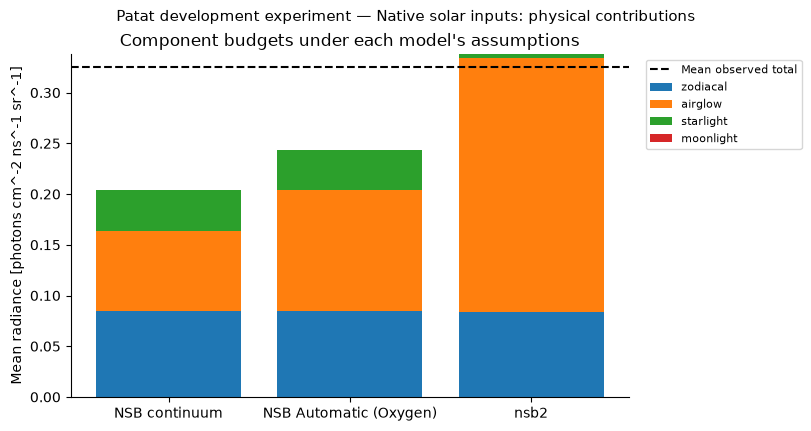

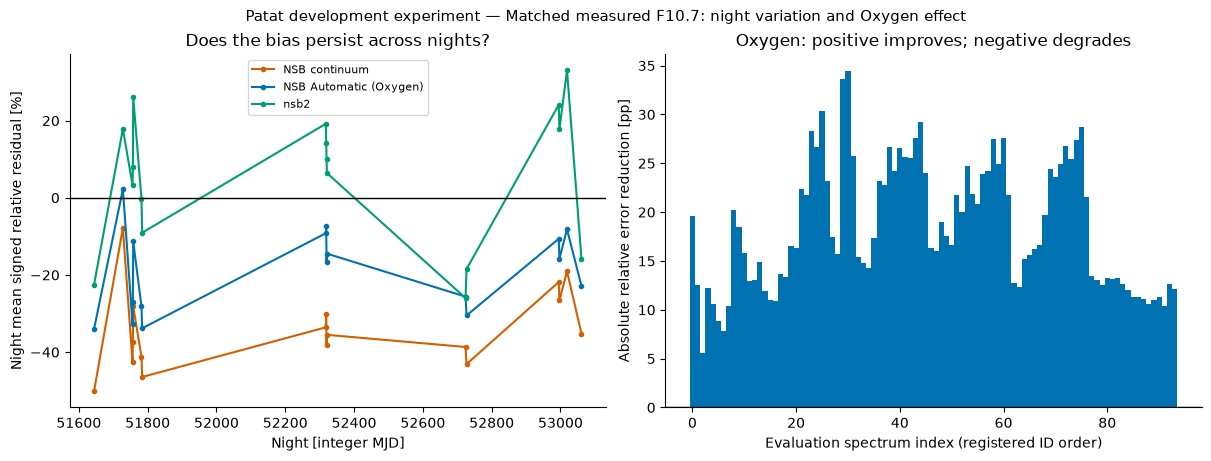

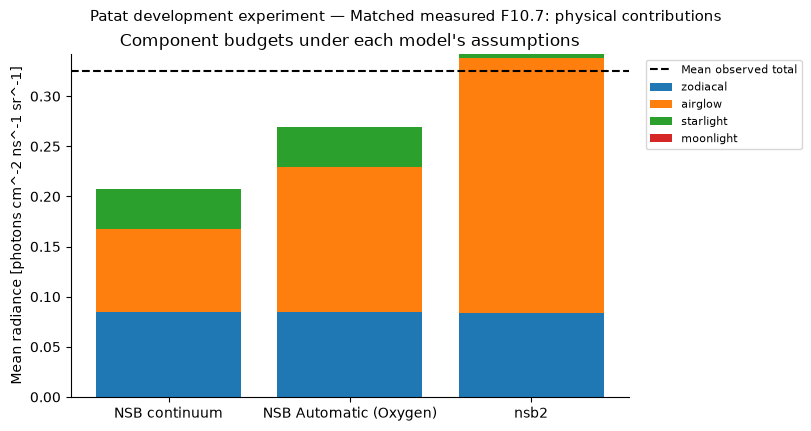

In [27]:
for scenario in metrics:
    values = evaluation_values(scenario)
    residuals = {m: (p-y)/y for m,p in values.items()}
    nights = np.array([rows[i]["night"] for i in evaluation])
    unique_nights = np.unique(nights)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    for model, residual in residuals.items():
        axes[0].plot(unique_nights, [100*np.mean(residual[nights == night]) for night in unique_nights], marker="o", markersize=3, color=COLORS[model], label=DISPLAY_NAMES[model])
    axes[0].axhline(0, color="black", lw=1)
    axes[0].set(xlabel="Night [integer MJD]", ylabel="Night mean signed relative residual [%]", title="Does the bias persist across nights?")
    axes[0].legend(fontsize=8)
    delta = 100*(abs(residuals["NSB continuum"])-abs(residuals["NSB Automatic"]))
    axes[1].bar(range(len(y)), delta, color=np.where(delta >= 0, COLORS["NSB Automatic"], COLORS["NSB continuum"]), width=1)
    axes[1].axhline(0, color="black", lw=1)
    axes[1].set(xlabel="Evaluation spectrum index (registered ID order)", ylabel="Absolute relative error reduction [pp]", title="Oxygen: positive improves; negative degrades")
    show_figure(fig, f"{SCENARIOS[scenario]}: night variation and Oxygen effect")
    fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
    bottom = np.zeros(len(MODELS))
    for part in COMPONENTS:
        means = np.array([np.mean([predictions[scenario][m][i]["components"][part] for i in evaluation]) for m in MODELS])
        ax.bar([DISPLAY_NAMES[m] for m in MODELS], means, bottom=bottom, label=part)
        bottom += means
    ax.axhline(np.mean(y), color="black", ls="--", label="Mean observed total")
    ax.set(ylabel=f"Mean radiance [{UNIT}]", title="Component budgets under each model's assumptions")
    ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
    show_figure(fig, f"{SCENARIOS[scenario]}: physical contributions")


### Oxygen spectral features and solar-input sensitivity

The spectral example uses the **first spectrum in the registered cohort order**,
not a spectrum selected for favorable agreement. It shows why including Oxygen can
change the broadband prediction, rather than measuring a spectral goodness of fit.
Observed **total** radiance is on air wavelengths; modeled **Airglow only** uses
vacuum-bin integrals divided by the 1 nm bin width. Other sky components, wavelength
conventions and instrumental resolution prevent a direct line-profile comparison.

The separate solar panel shows the change in absolute relative error between native
and matched inputs for every evaluation spectrum. Positive values mean the matched
input reduces error; negative values mean it increases error. The shaded 67–166 sfu
region is PALACE's training range. Viewing conditions covary with solar activity,
so this plot does not identify a causal solar effect or validate extrapolation.


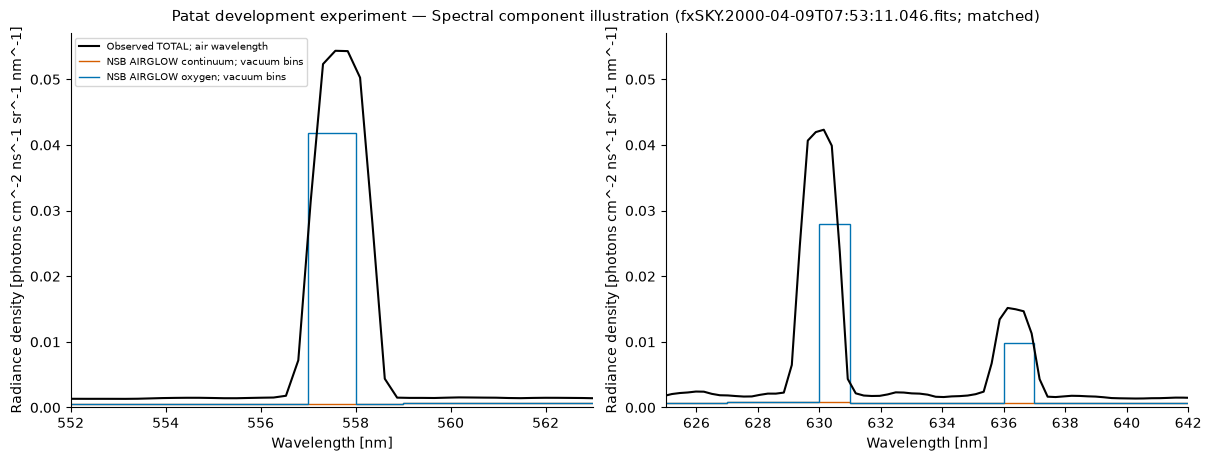

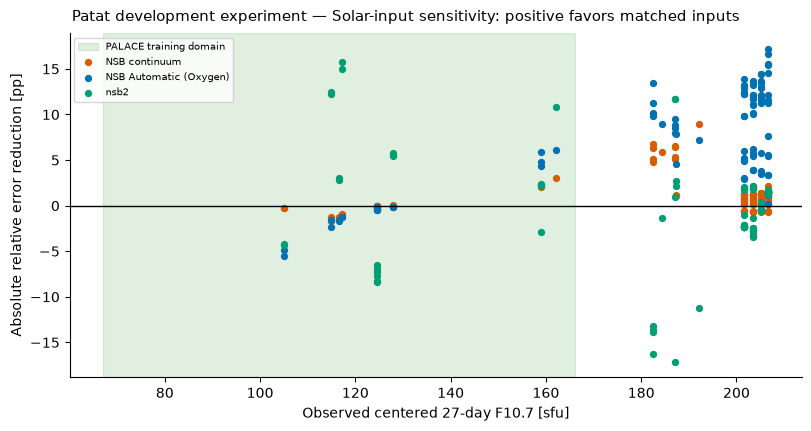

**79/103 observations outside PALACE's solar training range.**

In [28]:
if spectral:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    edges = np.array(spectral["vacuum_bin_edges_nm"])
    for ax, limits in zip(axes, ((552, 563), (625, 642)), strict=True):
        ax.plot(
            spectral["air_wavelength_nm"],
            spectral["observed_total_density"],
            color="black",
            label="Observed TOTAL; air wavelength",
        )
        for name in ("continuum", "oxygen"):
            ax.stairs(
                np.array(spectral[name]) / np.diff(edges),
                edges,
                label=f"NSB AIRGLOW {name}; vacuum bins",
                color=COLORS["NSB continuum" if name == "continuum" else "NSB Automatic"],
            )
        ax.set(xlim=limits, xlabel="Wavelength [nm]", ylabel=f"Radiance density [{UNIT} nm^-1]")
    axes[0].legend(fontsize=7)
    show_figure(fig, f"Spectral component illustration ({spectral['id']}; {spectral['scenario']})")
    if {"native", "matched"} <= set(metrics):
        fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
        f27 = np.array([rows[i]["f27"] for i in evaluation])
        ax.axvspan(67, 166, alpha=0.12, color="green", label="PALACE training domain")
        for model in MODELS:
            native = np.array([r["total"] for r in predictions["native"][model]])[evaluation]
            matched = np.array([r["total"] for r in predictions["matched"][model]])[evaluation]
            ax.scatter(f27, 100 * (abs(native - y) - abs(matched - y)) / y, s=18, color=COLORS[model], label=DISPLAY_NAMES[model])
        ax.axhline(0, color="black", lw=1)
        ax.set(
            xlabel="Observed centered 27-day F10.7 [sfu]",
            ylabel="Absolute relative error reduction [pp]",
        )
        ax.legend(fontsize=7)
        show_figure(fig, "Solar-input sensitivity: positive favors matched inputs")
    else:
        display(Markdown("**Solar sensitivity unavailable:** both native and matched scenarios must be valid."))
    if "solar" in provenance:
        display(
            Markdown(
                f"**{provenance['solar']['outside_palace_training']}/103 observations outside PALACE's solar training range.**"
            )
        )


## 5. Conclusions and limits of the evidence


In [29]:
complete_campaign = set(metrics) == {"native", "matched"} and not failures
if not complete_campaign:
    display(Markdown("**Incomplete assessment.** The two-scenario campaign is not complete. Valid scenario results above are descriptive only; no overall comparative conclusion is drawn. Inspect availability and failures in the appendix."))
else:
    display(Markdown("Both solar scenarios are complete. The following conclusions refer to this development cohort and its stated spectral assumptions."))
    for scenario in ("native", "matched"):
        result = metrics[scenario]
        display(Markdown(f"### {SCENARIOS[scenario]}"))
        for reference in ("nsb2", "baseline", "NSB continuum"):
            difference, interval = paired_comparison(result, "NSB Automatic", reference)
            display(Markdown(comparison_text(difference, interval, DISPLAY_NAMES[reference])))
        values = evaluation_values(scenario)
        reduction = abs(values["NSB continuum"]-y)-abs(values["NSB Automatic"]-y)
        improved, degraded = int(np.sum(reduction > 0)), int(np.sum(reduction < 0))
        display(Markdown(f"Including Oxygen reduces absolute error in **{improved}/{len(y)}** evaluation spectra, increases it in **{degraded}/{len(y)}**, and leaves **{int(np.sum(reduction == 0))}** unchanged. This describes a controlled model change; it does not independently validate the Oxygen model."))


Both solar scenarios are complete. The following conclusions refer to this development cohort and its stated spectral assumptions.

### Native solar inputs

**NSB Automatic − nsb2: +6.80 pp** (paired 95% CI +1.03 to +12.85 pp): higher NSB error; registered 10 pp practical margin not established.

**NSB Automatic − Calibration baseline: +8.64 pp** (paired 95% CI +1.03 to +13.51 pp): higher NSB error; registered 10 pp practical margin not established.

**NSB Automatic − NSB continuum: -12.22 pp** (paired 95% CI -12.85 to -11.17 pp): lower NSB error; registered 10 pp practical margin established.

...

### Matched measured F10.7

**NSB Automatic − nsb2: -0.85 pp** (paired 95% CI -5.71 to +5.58 pp): no difference established; equivalence is not established either; registered 10 pp practical margin not established.

**NSB Automatic − Calibration baseline: +1.33 pp** (paired 95% CI -4.61 to +6.08 pp): no difference established; equivalence is not established either; registered 10 pp practical margin not established.

**NSB Automatic − NSB continuum: -18.45 pp** (paired 95% CI -20.29 to -14.44 pp): lower NSB error; registered 10 pp practical margin established.

Including Oxygen reduces absolute error in **94/94** evaluation spectra, increases it in **0/94**, and leaves **0** unchanged. This describes a controlled model change; it does not independently validate the Oxygen model.

### What these results establish — and what remains open

This comparison quantifies agreement with a restricted Paranal dark-time cohort.
It tests the practical consequences of Oxygen and solar-input choices under the
registered assumptions. A baseline with lower error is a meaningful result:
a physical model must demonstrate added predictive value beyond local calibration.

**Development dependence.** Patat observations informed Oxygen development.
Separating calibration and evaluation nights protects the baseline fit, but does
not make the evaluation partition independent of model development. An independent
post-development cohort with compatible diffuse calibration is needed to assess
generalization. These results establish neither CTAO site calibration nor global
sky accuracy, and do not test bright Moon, twilight or the full default band.

**Physical comparability.** Missing non-oxygen emissions and molecular absorption,
different stellar populations, the research-only Starlight spectral proxy and
differing propagation conventions limit physical equivalence. Component budget
differences cannot uniquely identify the cause of a total-radiance discrepancy.

**Uncertainty.** FORS flux calibration has shared few-percent uncertainty; no
per-spectrum statistical uncertainty is supplied. Night bootstrap intervals cover
sampling variability, not these systematics or a complete model uncertainty budget.
An interval crossing zero establishes neither superiority nor equivalence.
Solar extrapolations and night-to-night patterns should be considered alongside
mean errors before using this assessment for observational planning.


## Technical appendix — reproducibility and numerical safeguards

The scientific conclusions above use only the current kernel's observations and
predictions. This appendix documents the safeguards that make them reproducible.

- **Observation identity:** the complete Patat archive and extracted FITS inventory
  are checksum-verified, including cache reuse. A registered mirror supplies the
  same bytes. Unsafe paths, links and duplicate archive members are rejected.
  The ID/night/partition checksum fixes the 103-spectrum cohort and exclusions.
- **Measurement:** photon radiance is the exact integral of wavelength times the
  piecewise-linear energy spectrum, using quadratic Simpson integration on each
  clipped interval. Å→cm, s→ns and arcsec²→sr conversions are explicit. The nsb2/Rieke
  reference uses the registered in-band source-grid trapezoids, a distinct operator.
- **Solar identity:** matched analysis requires the checksum-pinned NOAA source and
  27 complete UTC days (13 on each side). No interpolation, imputation or fit is
  used. Changed bytes or incomplete coverage disable the matched scenario.
- **Model identity:** the public restricted-band evaluator supplies Oxygen and
  continuum predictions. An early runtime assertion checks Automatic/Oxygen
  agreement; the moonless cohort requires zero modeled moonlight. nsb2's source
  URLs, cache hashes and installed package versions are recorded.
- **Export:** unless disabled, one JSON record and a detached SHA-256
  are written to `OUTPUT`. The record retains all observations, component predictions,
  metrics, paired intervals, exclusions, availability and runtime identities.
  Each run replaces `latest.json` and its digest. Figures are displayed only in
  the notebook and are not exported as separate files. The record and digest
  are optional for reading the notebook. Checksums detect changes, not authorship.

Save the notebook before an archival run: its on-disk hash excludes unsaved editor
changes. The scientific-definition hash describes the functions submitted to this
kernel. No repository identity is inferred. Changes to the scientific methodology
require a deliberate protocol revision.


In [30]:
def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def record_digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()


def scientific_signature(history):
    """Hash normalized scientific definitions actually submitted to this kernel."""
    required = set(
        "acquire extract linear_integral measured_radiance photon_density exclusion load_cohort solar_windows reference_integral starlight_fraction Models align baseline errors scores".split()
    )
    definitions = {}
    for source in history:
        try:
            tree = ast.parse(source)
        except SyntaxError:
            continue  # unrelated interactive magics are not scientific definitions
        for node in tree.body:
            if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in required:
                definitions[node.name] = ast.dump(node, include_attributes=False)
    if set(definitions) != required:
        raise ValueError("Run all scientific definition cells before recording results")
    return record_digest(definitions)


def make_record():
    compact = [{k: v for k, v in r.items() if k not in ("wave", "energy")} for r in rows]
    dependencies = {d.metadata["Name"]: d.version for d in metadata.distributions()}
    protocol = {
        "name": "patat-fors1-365-650-v1",
        "scientific_code_sha256": scientific_signature(
            get_ipython().history_manager.input_hist_raw
        ),
        "dataset_sha256": PATAT_SHA,
        "cohort_sha256": selection["identity_sha256"],
        "band_nm": [365, 650],
        "unit": UNIT,
        "measurement": "exact integral of wavelength times piecewise-linear energy; air grid",
        "reference_integration": "in-band grid-node trapezoid; public template resolver",
        "solar": provenance.get("solar", {}),
        "scenarios": sorted(metrics),
        "calibration_nights": sorted(CALIBRATION_NIGHTS),
        "baseline": "calibration spectrum median; fixed during resampling",
        "statistical_definition": "equal-spectrum MAE/RMSE/signed bias and medians; whole-night percentile bootstrap",
        "repetitions": REPETITIONS,
        "seed": SEED,
        "practical_margin": PRACTICAL_MARGIN,
        "invalid_predictions": "whole scenario invalid; no intersection scoring",
        "models": list(MODELS),
        "site": SITE,
        "starlight": {
            "assumption": "research-only Rieke photon fraction",
            "fraction": provenance.get("starlight_band_fraction"),
        },
        "reference": provenance.get("nsb2", {}),
        "external_sources": provenance.get("astropy_input_cache", {}),
        "dependencies": {
            k: metadata.version(k)
            for k in (
                "numpy", "astropy", "matplotlib", "siderust", "tempoch", "nsb-py", "nsb2",
                "astropy-iers-data", "scipy", "healpy", "scikit-learn", "dust_extinction",
            )
        },
    }
    return {
        "schema": 1,
        "classification": LABEL,
        "mode": "observational",
        "complete": True
        and set(metrics) == {"native", "matched"}
        and not failures,
        "independent_validation": False,
        "created_utc": datetime.now(UTC).isoformat(),
        "protocol": protocol,
        "provenance": provenance,
        "observations": compact,
        "predictions": predictions,
        "metrics": metrics,
        "availability": availability,
        "failures": failures,
        "spectral": spectral,
        "environment": {
            "python": sys.version,
            "platform": platform.platform(),
            "packages": dependencies,
        },
    }


def save_record(record, directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / "latest.json"
    with path.open("w") as stream:
        stream.write(canonical(record) + "\n")
    path.with_suffix(".sha256").write_text(sha256(path) + "\n")
    return path


notebook_file = Path("NSB_Validation.ipynb")
if notebook_file.is_file():
    notebook_payload = json.loads(notebook_file.read_text())
    sources = [
        "".join(cell["source"]) for cell in notebook_payload["cells"] if cell["cell_type"] == "code"
    ]
    provenance["notebook"] = {
        "file_sha256": sha256(notebook_file),
        "on_disk_code_sha256": record_digest(sources),
        "scope": "on-disk file; save editor before Run All",
    }
else:
    provenance["notebook"] = {"scope": "not found in working directory; save notebook with results"}
record = make_record()
result_path = None
if OUTPUT:
    result_path = save_record(record, OUTPUT)
    display(Markdown(f"Saved **{result_path.resolve()}** and detached SHA-256."))


Saved **/home/valles/workspace/nsb/notebooks/validation-results/latest.json** and detached SHA-256.

In [31]:
display(Markdown(f"**{LABEL}** — complete observational campaign: **{record['complete']}**"))
display(
    Markdown(
        "Runtime and data provenance are retained in `record['provenance']`; "
        "all installed package versions in `record['environment']`."
    )
)
if not record["complete"]:
    raise RuntimeError(
        "Incomplete scientific campaign: inspect availability/failures in the saved record"
    )

**Patat development experiment** — complete observational campaign: **True**

Runtime and data provenance are retained in `record['provenance']`; all installed package versions in `record['environment']`.

### Historical context — separate from the current execution

Computed values and figures above come from this kernel. The following are
**historical context only**, never substituted for computation: matched relative
MAE was approximately continuum **35.027%**, Automatic/Oxygen **16.573%**, nsb2 **17.425%**,
and calibration baseline **15.245%**. Historical Oxygen−nsb2 relative-MAE difference
was −0.852 pp with paired 95% CI [−5.709, 5.576] pp: **superiority was not established**.
The baseline had lower relative MAE. Original benchmark revision
`1b2556727205694c7765ef0d254c5d1b301582ec`, Oxygen numerical revision
`168e73dae89060423eebc344871b0084d217c305`, and later merge
`57584ee298f25f8af7a6f169d71e87f8a59eea9a` are distinct identities.
A new version agreeing numerically is not a byte-identical historical replay.


### References and data credits

Sources to cite: [Patat (2008), A&A 481, 575](https://www.aanda.org/articles/aa/pdf/2008/14/aa9279-07.pdf);
[Roellinghoff, Spencer & Funk (2025), A&A 698, A212](https://www.aanda.org/articles/aa/pdf/2025/06/aa54532-25.pdf);
[nsb2 source and acknowledgements](https://gerritro.github.io/nsb2/acknowledgements.html);
[NSB Oxygen development evidence](https://github.com/VPRamon/NSB/blob/57584ee298f25f8af7a6f169d71e87f8a59eea9a/docs/nsb_components/airglow/validation/oxygen-and-calibration-v1.md).
The stellar path uses ESA Gaia data processed by DPAC and HEALPix/healpy; retain
original source credits and data terms. No private validation source is used.
